# Pipeline agentico: tool-calling + vision + RPA

Primera prueba de extremo a extremo del patron que vamos a usar para el agente (fase 3-4 de `PROJECT.md`): un LLM orquestador con **tool-calling real** decide, a partir de una instruccion en lenguaje natural, que herramientas llamar y con que argumentos -- nosotros definimos esas herramientas como funciones Python normales.

```
instruccion en lenguaje natural
        |
        v
  orquestador (GPT-OSS-120B via Groq, tool-calling nativo)
        |-- localizar_elemento(descripcion)
        |       captura de pantalla (mss) + UI-TARS (vision_tools.py) -> (x, y)
        |
        `-- click(x, y)
                pyautogui.click(x, y)  <- el clic real
```

UI-TARS **no** es el orquestador: no tiene tool-calling nativo, devuelve texto plano en su propio formato de accion. Por eso vive escondido dentro de la tool `localizar_elemento`, y quien decide la secuencia de llamadas es el modelo de Groq.

Objetivo de esta prueba: que el agente, a partir de "haz clic en el boton Entrar", localice el boton solo y haga clic de verdad sobre la ventana real de GestCorp 98.

In [1]:
# En Windows, si el proceso no se declara "DPI aware" las coordenadas que
# usa pyautogui pueden no coincidir 1:1 con los pixeles reales que captura
# mss (la pantalla se ve escalada de forma distinta para cada uno). Hay que
# hacer esto ANTES de usar mss/pyautogui, lo antes posible en el kernel.
import ctypes

try:
    ctypes.windll.shcore.SetProcessDpiAwareness(1)  # PROCESS_SYSTEM_DPI_AWARE
except Exception as exc:
    print(f"no se pudo fijar DPI awareness (quiza no es Windows): {exc}")

In [2]:
import os

from dotenv import load_dotenv

load_dotenv("../.env")  # carga GROQ_API_KEY desde el .env en la raiz del proyecto

assert os.environ.get("GROQ_API_KEY"), (
    "Falta GROQ_API_KEY. Rellena la clave en el archivo .env de la raiz del "
    "proyecto (la consigues en https://console.groq.com/) y vuelve a "
    "ejecutar esta celda."
)


## Las tools

`localizar_elemento` envuelve `vision_tools.localizar_elemento_en_pantalla` (la misma logica de UI-TARS ya validada en `vision_evaluation.ipynb`, extraida a un modulo aparte para no duplicarla). `click` ejecuta el clic real con `pyautogui`. `escribir_texto` hace clic en un campo, lo vacia y escribe el texto dado.

`verificar_en_pantalla` es la que hace al agente **a prueba de errores**: despues de cada accion saca otra captura y le pregunta a UI-TARS (el mismo modelo, ya cargado) si se ve el resultado esperado, con una respuesta que empieza por SI o NO. Antes lo intentamos con OCR (RapidOCR), pero fallaba con el texto de los campos (leia `"seon]"` donde ponia `"Lucas"`); UI-TARS, en cambio, entiende la pantalla y responde en lenguaje natural.

El docstring de cada tool es lo que el LLM orquestador lee para decidir cuando usarla -- tiene que ser claro.

In [3]:
import pyautogui
import pyperclip
from langchain_core.tools import tool

import vision_tools


@tool
def localizar_elemento(descripcion: str) -> dict:
    """Localiza un elemento de la interfaz visible AHORA MISMO en pantalla,
    a partir de su descripcion en lenguaje natural (p.ej. "el boton Entrar",
    "el campo de texto Usuario"). Hace una captura de pantalla real y usa un
    modelo de vision para encontrarlo. Devuelve las coordenadas de pantalla
    (x, y) donde hacer clic.
    """
    resultado = vision_tools.localizar_elemento_en_pantalla(descripcion)
    return {"x": resultado["x"], "y": resultado["y"]}


@tool
def click(x: int, y: int) -> str:
    """Hace clic con el boton izquierdo del raton en las coordenadas de
    pantalla (x, y) dadas. Usa primero `localizar_elemento` para obtener
    las coordenadas de lo que quieras clicar.
    """
    pyautogui.click(x, y)
    return f"clic hecho en ({x}, {y})"


@tool
def borrar_campo(x: int, y: int) -> str:
    """Vacia un campo de texto: hace clic en las coordenadas (x, y) para
    situar el cursor en el y borra todo su contenido. Usalo SIEMPRE antes
    de `escribir_texto` (el campo puede venir ya relleno) y para corregir
    un campo mal escrito. Usa primero `localizar_elemento` para obtener
    las coordenadas del campo.
    """
    pyautogui.click(x, y)
    # ir al final y borrar hacia atras. NO usamos Shift+Home para seleccionar
    # todo: pyautogui en Windows manda Home como tecla del teclado numerico y,
    # con Bloq Num activado, Windows suelta el Shift y no selecciona nada.
    pyautogui.press("end")
    pyautogui.press("backspace", presses=50)
    return f"campo vaciado en ({x}, {y})"


@tool
def escribir_texto(x: int, y: int, texto: str) -> str:
    """Hace clic en las coordenadas (x, y) de un campo y escribe el texto
    dado con el teclado. NO borra lo que hubiera antes: se AÑADE al final,
    asi que llama antes a `borrar_campo`.
    """
    pyautogui.click(x, y)
    pyautogui.press("end")
    # pegar en vez de teclear: typewrite se salta en silencio los caracteres
    # que no estan en su lista de teclas (tildes, ñ, €...)
    pyperclip.copy(texto)
    pyautogui.hotkey("ctrl", "v")
    return f"escrito '{texto}' en ({x}, {y})"


@tool
def verificar_en_pantalla(pregunta: str, elemento: str = "") -> str:
    """Hace una captura de pantalla AHORA MISMO y le pregunta a un modelo
    de vision si se cumple lo que esperas tras tu ultima accion. Ese modelo
    SOLO ve la imagen: no conoce la aplicacion ni tu objetivo, asi que la
    pregunta tiene que ser concreta, de si/no y sobre algo visible.
    Si `elemento` describe un elemento concreto (p.ej. "el campo de texto
    Nombre del formulario Alta de cliente"), primero se localiza y solo se
    mira una zona pequena alrededor de el -- usalo para campos. Dejalo
    vacio para mirar toda la ventana -- usalo tras pulsar un boton, cuando
    el cambio puede aparecer en cualquier parte (otra pantalla, un aviso,
    una fila nueva en un listado). La respuesta empieza por SI o NO.
    """
    if "contrase" in elemento.lower() or "password" in elemento.lower():
        return (
            "NO VERIFICABLE: un campo de contrasena muestra asteriscos y no se "
            "puede leer. No lo verifiques; sigue con el siguiente paso."
        )
    pregunta_formateada = (
        f"{pregunta} Responde empezando por 'SI' o 'NO' y despues describe "
        "brevemente lo que ves. No respondas con coordenadas."
    )
    if elemento:
        coords = vision_tools.localizar_elemento_en_pantalla(elemento)
        return vision_tools.preguntar_sobre_pantalla(
            pregunta_formateada, x=coords["x"], y=coords["y"]
        )
    return vision_tools.preguntar_sobre_pantalla(pregunta_formateada)

## El orquestador: LangChain v1 (`create_agent`) + GPT-OSS-120B (Groq)

`create_agent` (API de agentes de `langchain` v1, sobre LangGraph por debajo) monta el bucle estandar (el LLM decide una tool -> se ejecuta de verdad -> el resultado vuelve al LLM -> repite hasta que ya no hace falta mas) sin tener que escribir el grafo a mano.

In [4]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

# Version compacta: lo que hace cada tool ya lo cuentan sus docstrings (el
# modelo las recibe igualmente), aqui solo va el METODO. Cada token de este
# prompt se reenvia en CADA paso del agente, asi que cuanto mas corto, mas
# intentos caben en el limite diario de Groq.
SYSTEM_PROMPT = """Eres un agente de RPA que maneja una aplicación de escritorio real (GestCorp 98)
a través de tus tools. El usuario te da un OBJETIVO y los pasos para lograrlo:
síguelos en orden hasta conseguir el objetivo completo.

CÓMO ACTUAR EN LA PANTALLA
No conoces las coordenadas de nada. Para CADA acción que te pida el usuario
(pulsar un botón, una pestaña, un desplegable, una opción de una lista o
rellenar un campo):
1. Llama a `localizar_elemento` describiendo el elemento con el nombre exacto
   que te dio el usuario en sus instrucciones (p. ej. el botón "Entrar", el
   campo "Nombre", el desplegable a la derecha de "Producto:"). No lo resumas
   ni le cambies el nombre. Un modelo de visión mira la pantalla y te devuelve
   sus coordenadas (x, y).
2. Usa esas coordenadas inmediatamente:
   - botón, pestaña, desplegable u opción de una lista -> `click(x, y)`
   - campo de texto -> `escribir_texto(x, y, texto)`
Localiza siempre justo antes de actuar: cuando cambias de pestaña o abres un
desplegable la pantalla cambia y las coordenadas anteriores ya no valen.

VERIFICAR Y CORREGIR ANTES DE ENVIAR UN FORMULARIO
`verificar_en_pantalla` y `borrar_campo` se usan SOLO en dos momentos:

A) Pestaña "Clientes", formulario "Alta de cliente": cuando hayas rellenado
   todos los campos que te pidió el usuario y ANTES de pulsar el botón
   "Añadir cliente".
B) Pestaña "Pedidos", formulario "Nuevo pedido": cuando hayas elegido el
   cliente, el producto y escrito la cantidad que te pidió el usuario y ANTES
   de pulsar el botón "Crear pedido".

En cada uno de esos dos momentos:
1. Llama a `verificar_en_pantalla` y pregunta si los campos que te pidieron
   rellenar contienen exactamente los valores pedidos (nombra cada campo y su
   valor). Pide que responda solo SI o NO y, si es NO, que diga qué campos no
   contienen el valor pedido.
2. Si responde SI: pulsa el botón ("Añadir cliente" o "Crear pedido") con
   `localizar_elemento` -> `click`, y sigue con el siguiente paso.
3. Si responde NO: corrige solo los campos que fallan.
   - Campo de texto: `localizar_elemento` -> `borrar_campo` -> `escribir_texto`.
   - Desplegable (Cliente y Producto en Pedidos): ábrelo y vuelve a elegir la
     opción correcta con `localizar_elemento` -> `click`.
   Después vuelve al punto 1.
Repite hasta que la verificación responda SI. Nunca pulses "Añadir cliente"
ni "Crear pedido" sin una verificación con respuesta SI justo antes.

Fuera de esos dos momentos no uses `verificar_en_pantalla` ni `borrar_campo`.
Tampoco en el login: la contraseña sale en asteriscos y no se puede verificar.

TERMINAR: cuando completes el objetivo, tu último mensaje empieza por
"RESUMEN FINAL" y dice qué pasos hiciste y si se cumplió el objetivo.
"""

# reasoning_effort="low": gpt-oss "piensa" menos antes de cada tool call.
# Esos tokens de razonamiento tambien cuentan para el limite diario.
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0, reasoning_effort="low")
agent = create_agent(
    model,
    tools=[localizar_elemento, click, escribir_texto, borrar_campo, verificar_en_pantalla],
    system_prompt=SYSTEM_PROMPT,
)

## Precargar el modelo de visión (UI-TARS)

`localizar_elemento` carga UI-TARS-7B la primera vez que se usa (es un modelo pesado, tarda bastante). Si esa primera carga ocurriera dentro de la celda que ya tiene la app abierta y al agente ejecutando, te quedarias un buen rato con la ventana abierta sin que pase nada visible. Por eso lo cargamos aqui, en su propia celda, antes de abrir la app.

In [5]:
import time

import vision_tools

t0 = time.perf_counter()
vision_tools.precargar_modelo_vision()
print(f"modelo UI-TARS cargado en {time.perf_counter() - t0:.1f}s")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

UI-TARS cargado en: cuda:0
modelo UI-TARS cargado en 24.0s


## Abrir GestCorp 98 en la mitad derecha de la pantalla

Como proceso aparte (si fuera en el mismo proceso, `root.mainloop()` de Tkinter bloquearia el kernel de Jupyter).

La app arranca maximizada, asi que la "restauramos" y la colocamos en la mitad derecha: a la izquierda te queda el notebook para ver en directo lo que va haciendo el agente, y a la derecha la app.

Ademas fijamos la **region de captura** a la ventana de la app (`vision_tools.fijar_region_captura`). Sin esto, las capturas incluirian tambien el notebook de la izquierda, y UI-TARS podria localizar "el campo Nombre" en el texto de tu prompt, o al verificar ver "Lucas" escrito en el propio notebook y dar la comprobacion por buena en falso.

Esta celda se ejecuta **una sola vez**; la de abajo (el agente) y el experimento se pueden repetir con la app abierta.

GestCorp 98 en (1280, 0), tamano 1280x1529


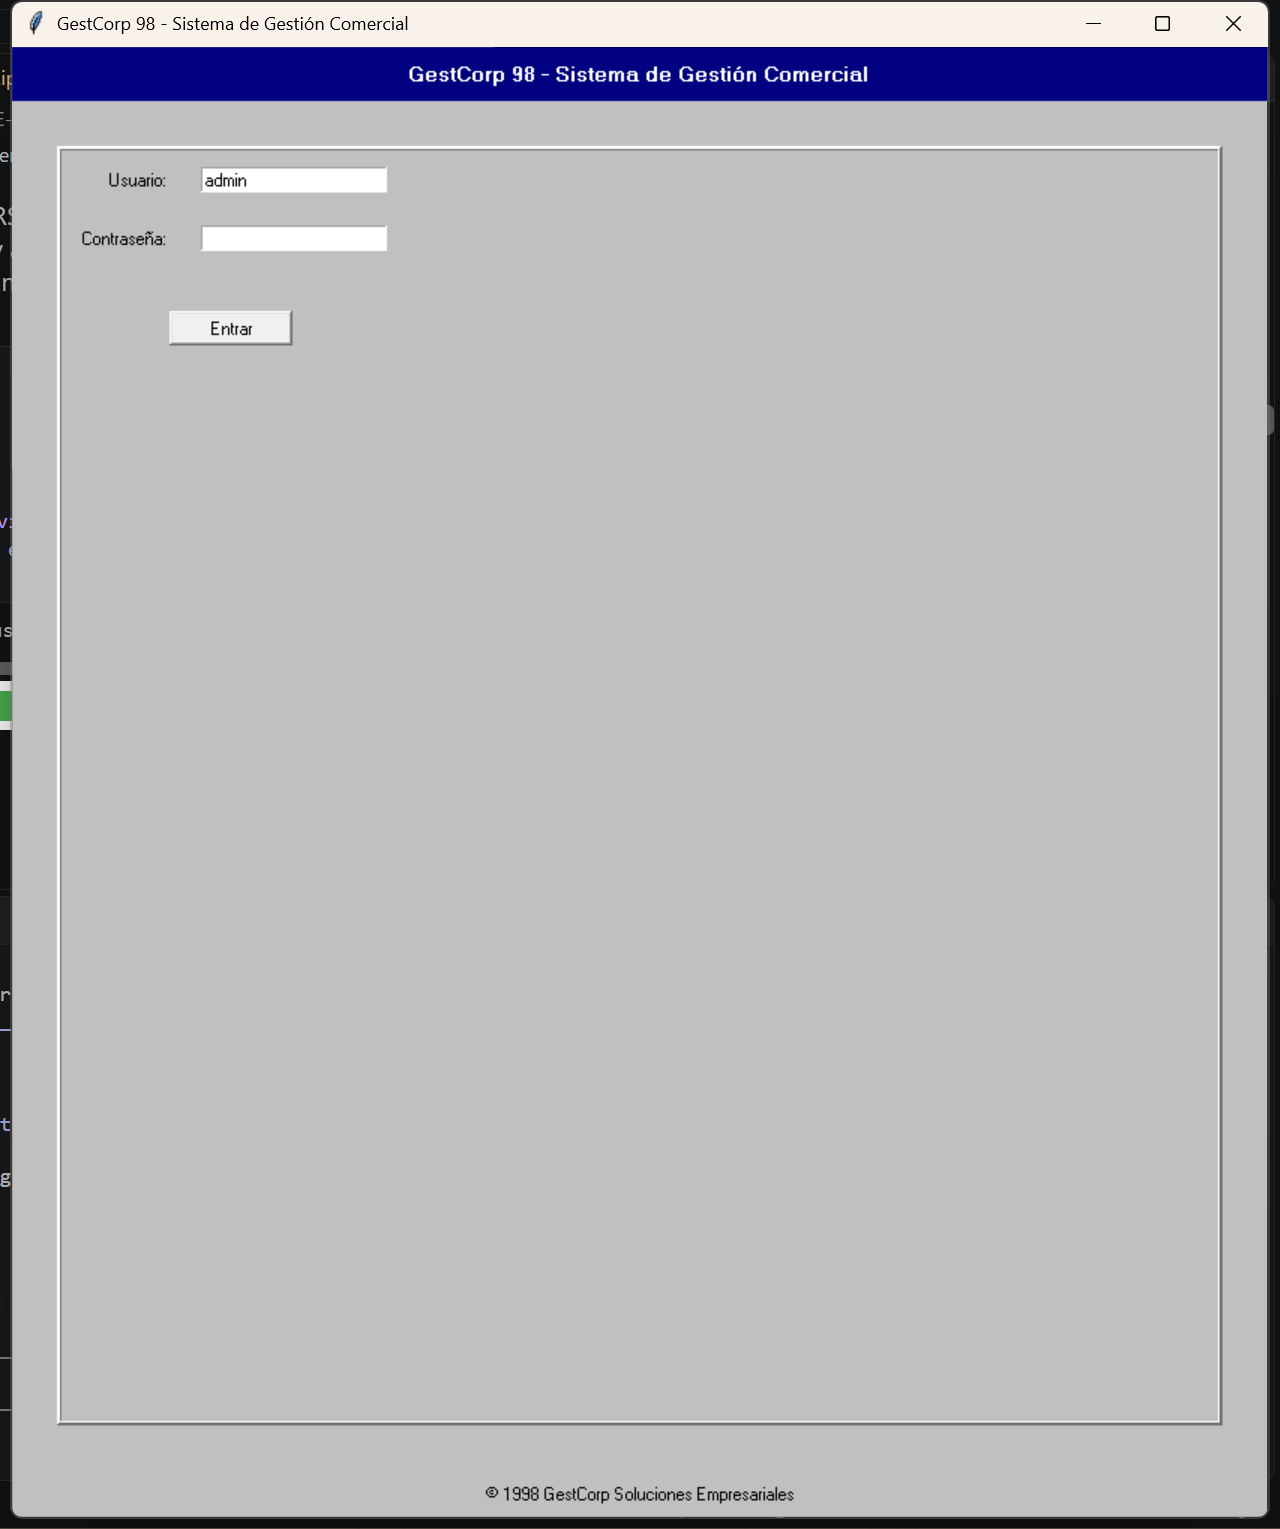

In [6]:
import ctypes.wintypes
import subprocess
import sys
import time

import pygetwindow as gw

TITULO_VENTANA = "GestCorp 98 - Sistema de Gestión Comercial"

proceso_gestcorp98 = subprocess.Popen([sys.executable, "-m", "gestcorp98.main"], cwd="..")

ventana = None
for _ in range(20):
    time.sleep(0.5)
    candidatas = gw.getWindowsWithTitle(TITULO_VENTANA)
    if candidatas:
        ventana = candidatas[0]
        break
if ventana is None:
    raise RuntimeError(f"no encontre la ventana '{TITULO_VENTANA}' tras 10s")

# zona util de la pantalla, sin la barra de tareas (SPI_GETWORKAREA)
area = ctypes.wintypes.RECT()
ctypes.windll.user32.SystemParametersInfoW(0x0030, 0, ctypes.byref(area), 0)
mitad = (area.right - area.left) // 2

# la app arranca maximizada ("zoomed"): hay que restaurarla antes de poder moverla
ventana.restore()
time.sleep(0.5)
ventana.moveTo(area.left + mitad, area.top)
ventana.resizeTo(mitad, area.bottom - area.top)
time.sleep(0.5)

vision_tools.fijar_region_captura(ventana.left, ventana.top, ventana.width, ventana.height)
print(f"GestCorp 98 en ({ventana.left}, {ventana.top}), tamano {ventana.width}x{ventana.height}")
vision_tools.capturar_pantalla()  # lo que vera el agente a partir de ahora

## Ejecutar el agente

Te pide la instruccion (p.ej. pega la de `prompts/login_alta_cliente.txt`), le da el foco a la app y lanza el agente. Usamos `agent.stream` en vez de `agent.invoke` para que cada mensaje (cada tool que decide llamar y lo que devuelve) se imprima **en cuanto ocurre**, no todo de golpe al final: asi lo vas viendo a la izquierda mientras la app se mueve a la derecha.

Puedes volver a ejecutar esta celda tantas veces como quieras sin cerrar la app.

aviso: activate() lanzo un error (Error code from Windows: 0 - La operación se completó correctamente.), sigo de todas formas
================================ Human Message =================================

OBJETIVO: dar de alta en GestCorp 98 un cliente nuevo llamado "Juan José" y crearle un pedido. PASO 1, INICIAR SESIÓN: estás en la ventana de login. Escribe "admin" en el campo "Contraseña" y pulsa el botón "Entrar". PASO 2, DAR DE ALTA EL CLIENTE: Arriba hay una tabla con los clientes existentes y abajo el formulario "Alta de cliente", con los campos Nombre, NIF y Email en la primera fila y Teléfono y Ciudad en la segunda. Escribe "Juan José" en el campo Nombre, "12345" en el campo NIF y "Jaén" en el campo Ciudad (Email y Teléfono se quedan vacíos). Después pulsa "Añadir cliente".PASO 3, CREAR EL PEDIDO: pulsa la pestaña "Pedidos" (arriba, junto a "Clientes"). En esta pestaña la palabra "Cliente" aparece dos veces, no las confundas: arriba, como cabecera de una columna de la tabla

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: localizar_elemento

{"x": 1521, "y": 240}
================================== Ai Message ==================================
Tool Calls:
  escribir_texto (fc_c4536cc9-cbe2-4139-90ab-d48b562248b4)
 Call ID: fc_c4536cc9-cbe2-4139-90ab-d48b562248b4
  Args:
    texto: admin
    x: 1521
    y: 240
================================= Tool Message =================================
Name: escribir_texto

escrito 'admin' en (1521, 240)
================================== Ai Message ==================================
Tool Calls:
  localizar_elemento (fc_c1c9f90f-f5f5-4343-b9ba-f2b7f7d1f62c)
 Call ID: fc_c1c9f90f-f5f5-4343-b9ba-f2b7f7d1f62c
  Args:
    descripcion: botón Entrar


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: localizar_elemento

{"x": 1510, "y": 327}
================================== Ai Message ==================================
Tool Calls:
  click (fc_ea152a6e-a858-4b22-afff-ebd511867be2)
 Call ID: fc_ea152a6e-a858-4b22-afff-ebd511867be2
  Args:
    x: 1510
    y: 327
================================= Tool Message =================================
Name: click

clic hecho en (1510, 327)
================================== Ai Message ==================================
Tool Calls:
  localizar_elemento (fc_a5a50836-68d2-4c29-99f7-3ee5ba96094b)
 Call ID: fc_a5a50836-68d2-4c29-99f7-3ee5ba96094b
  Args:
    descripcion: campo Nombre


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


... (27 outputs left out)

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: localizar_elemento

{"x": 1789, "y": 1456}
================================== Ai Message ==================================
>> paro sin terminar (finish_reason=stop); le pido que continue
================================ Human Message =================================

No has terminado. Continua con el siguiente paso pendiente del proceso.
================================== Ai Message ==================================
Tool Calls:
  click (fc_3d0893e3-8bfa-438f-82e2-b366b1c139fe)
 Call ID: fc_3d0893e3-8bfa-438f-82e2-b366b1c139fe
  Args:
    x: 1789
    y: 1456
================================= Tool Message =================================
Name: click

clic hecho en (1789, 1456)
================================== Ai Message ==================================

RESUMIn...RESUMEN FINAL  
- Inicié sesión escribiendo **admin** en el campo “Contraseña” y pulsando **Entrar**.  
- En la pestaña “Clientes” co

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: verificar_en_pantalla

SI. Se ve un nuevo registro en la tabla de pedidos con Cliente 'Juan José', Producto 'Palet de madera estándar' y Cantidad '3'.
================================== Ai Message ==================================

RESUMEN FINAL  
- Inicié sesión con la contraseña **admin** y pulsé **Entrar**.  
- En la pestaña **Clientes** completé el formulario “Alta de cliente” con Nombre **Juan José**, NIF **12345** y Ciudad **Jaén**, verifiqué los datos y pulsé **Añadir cliente**.  
- Cambié a la pestaña **Pedidos**, seleccioné en el desplegable **Cliente** a **Juan José**, en el desplegable **Producto** a **Palet de madera estándar**, introduje la **Cantidad 3**, verifiqué los campos y pulsé **Crear pedido**.  
- Verifiqué que el nuevo registro aparece en la tabla de pedidos con Cliente **Juan José**, Producto **Palet de madera estándar** y Cantidad **3**.  

Objetivo cumplido: el cliente está

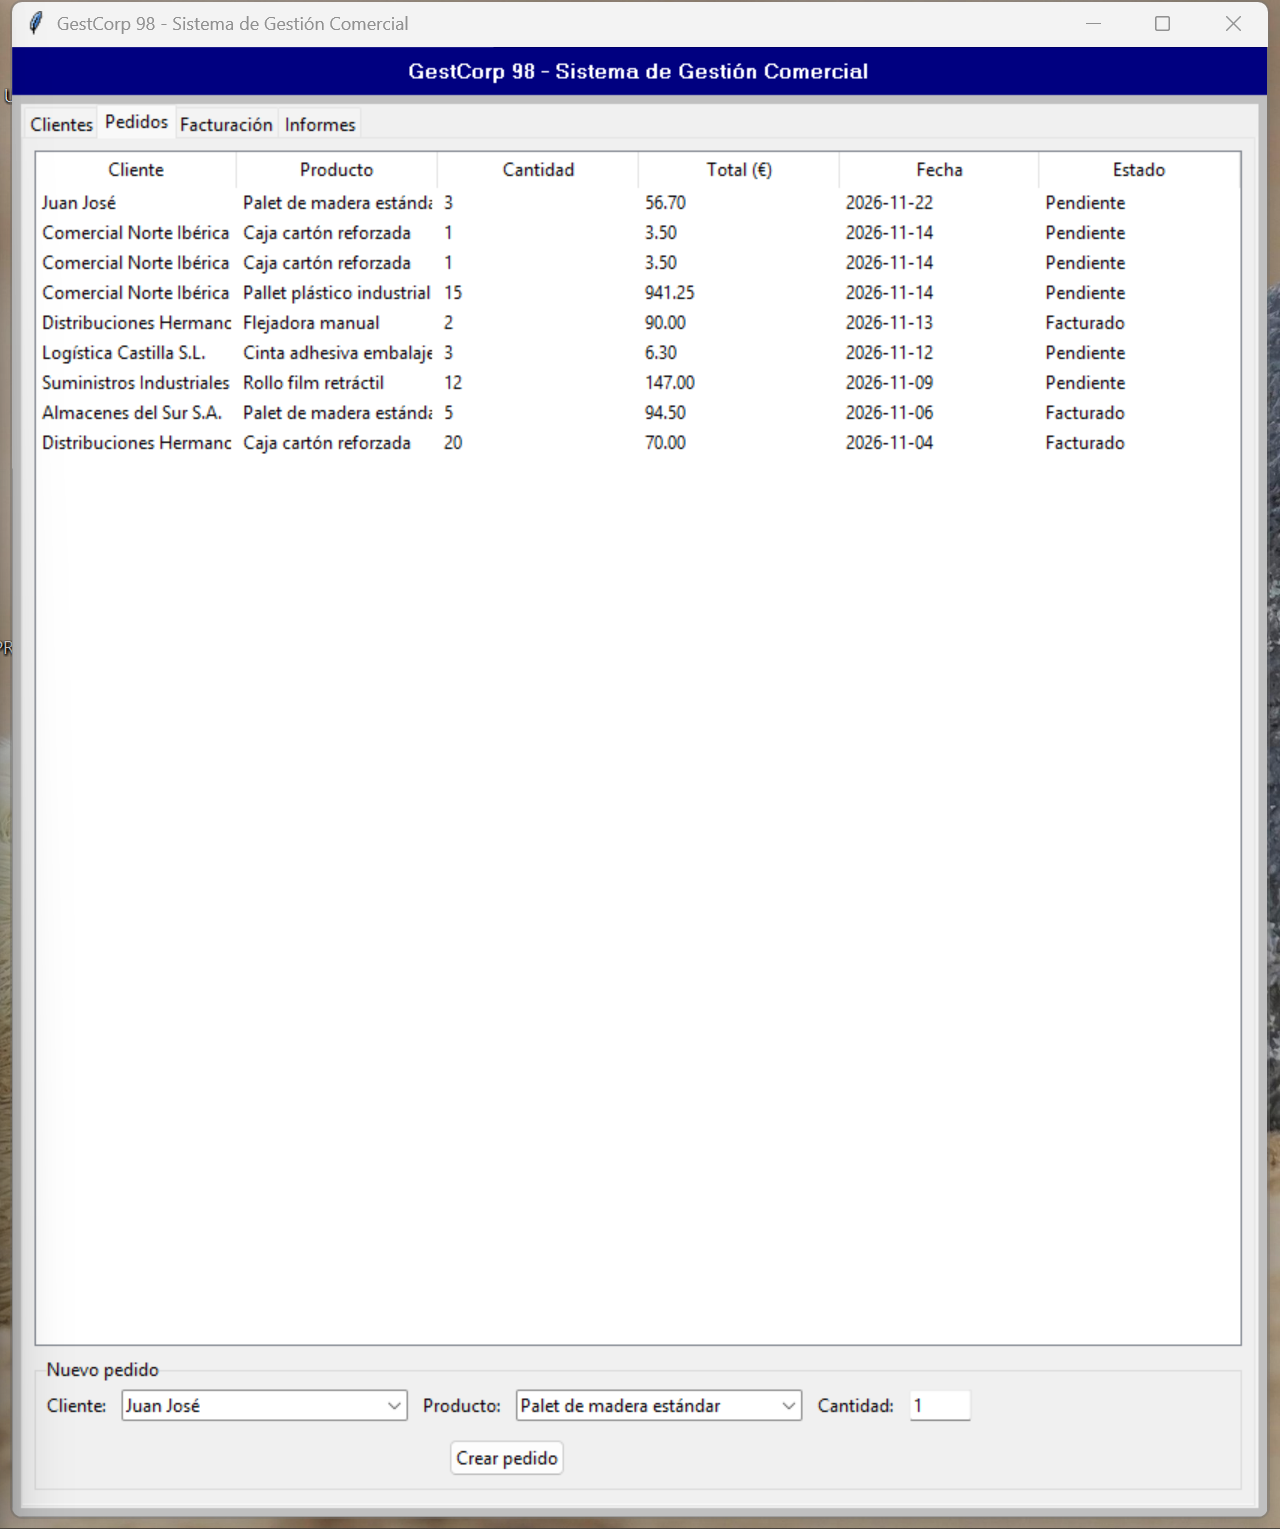

In [7]:
instruccion = input("Instruccion para el agente: ")

try:
    ventana.activate()
except Exception as exc:
    # pygetwindow a veces lanza aqui aunque el cambio de foco SI funcione
    # (restriccion de Windows sobre que proceso puede robar el foco); en
    # cualquier caso la primera accion del agente es un clic sobre la app
    print(f"aviso: activate() lanzo un error ({exc}), sigo de todas formas")
time.sleep(0.5)

# A veces el modelo devuelve un mensaje vacio a mitad de la tarea y el agente
# lo toma como "he terminado". Si el ultimo mensaje no es el RESUMEN FINAL que
# pide el system prompt, le decimos que continue (con todo el historial).
MAX_REANUDACIONES = 3
mensajes = [("user", instruccion)]
for intento in range(MAX_REANUDACIONES + 1):
    for estado in agent.stream({"messages": mensajes}, stream_mode="values"):
        estado["messages"][-1].pretty_print()
    mensajes = estado["messages"]
    final = mensajes[-1]
    if str(final.content).strip().startswith("RESUMEN FINAL"):
        break
    if intento == MAX_REANUDACIONES:
        print(">> el agente sigue parando sin terminar; me rindo")
        break
    print(
        f">> paro sin terminar (finish_reason="
        f"{final.response_metadata.get('finish_reason')}); le pido que continue"
    )
    mensajes = mensajes + [
        ("user", "No has terminado. Continua con el siguiente paso pendiente del proceso.")
    ]

time.sleep(1)  # dar tiempo a que la UI reaccione a la ultima accion
vision_tools.capturar_pantalla()

## Experimento: ¿puede UI-TARS responder preguntas, no solo localizar?

Prueba suelta, todavia sin conectarla a las tools ni al agente. Ejecutala con GestCorp 98 **todavia abierto**, tantas veces como quieras. Te pide dos cosas:

1. **La pregunta**, la que tu quieras (p.ej. "Que texto hay escrito en este campo? Responde solo con el texto" o "Aparece un cliente llamado Lucas en el listado? Responde si o no").
2. **El elemento en el que fijarse** (opcional): si escribes algo (p.ej. "el campo de texto Nombre del formulario Alta de cliente"), primero se localiza con UI-TARS y la pregunta se hace solo sobre un recorte alrededor de ese elemento. Si lo dejas vacio, la pregunta se hace sobre toda la ventana de la app.

Si responde bien a preguntas de verificacion, lo convertimos en una tool de verdad; si no, probamos otra cosa (p.ej. un segundo modelo tipo qwen2.5vl).

In [ ]:
pregunta = input("Pregunta para UI-TARS: ")
zona = input("Elemento en el que fijarse (deja vacio para mirar toda la ventana): ").strip()

if zona:
    coords = vision_tools.localizar_elemento_en_pantalla(zona)
    print(f"'{zona}' localizado en: ({coords['x']}, {coords['y']})")
    respuesta = vision_tools.preguntar_sobre_pantalla(pregunta, x=coords["x"], y=coords["y"])
else:
    respuesta = vision_tools.preguntar_sobre_pantalla(pregunta)

print(f"respuesta de UI-TARS: {respuesta!r}")

## Limpieza

Cierra el proceso de GestCorp 98 cuando termines de probar.

In [18]:
proceso_gestcorp98.terminate()